# Probability boxes for one five-dimensional event

The first three coordinates and last two coordinates are treated as independent probability blocks. For each block, randomly selected sample values define one-dimensional separators at the midpoints of adjacent selected values. The outer separators are the minimum and maximum of all samples. Empty cells and cells containing only one sample are discarded. Each retained box is shrunk to the coordinate range of its assigned samples.

For a retained box $B$, with $n_B$ of the original $N$ samples and hypervolume $V_B$, the constant density is

$$p_B = \frac{n_B}{N V_B}, \qquad \sum_B p_B V_B = \frac{N_{\mathrm{retained}}}{N}.$$

The product of the retained probabilities of the 3D and 2D blocks is the event's retained probability. Discarded sample probability is not redistributed. The chosen sample values set the separators; with uneven spacing, they do not generally coincide with the geometric centers of their final cells. The box weight is one for now.

In [1]:
import os
import shutil
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib_box_overlap")

from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc, rcParams, font_manager
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from cycler import cycler

project_root = Path.cwd()
if project_root.name == "validation":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from bo import make_event_boxes, pick_centers

my_colors = ['navy', 'coral', 'c', 'crimson', 'springgreen', 'gold',
             'dodgerblue', 'hotpink', 'forestgreen', 'moccasin', 'darkred', 'teal']
rc_params = {'axes.labelsize': 14,
             'axes.titlesize': 14,
             'legend.fontsize': 14,
             'xtick.labelsize': 12,
             'ytick.labelsize': 12,
             'text.usetex': True,
             'text.latex.preamble': r'\usepackage{txfonts}',
             'font.size': 14,
             'font.family': 'serif',
             'font.serif': 'times',
             'mathtext.default': 'sf',
             'lines.markeredgewidth': 1,
             'lines.linewidth': 2,
             'axes.prop_cycle': cycler(color=my_colors)}
rcParams.update(rc_params)
missing_tex = [name for name in ("latex", "dvipng") if shutil.which(name) is None]
if missing_tex:
    print(f"Install {', '.join(missing_tex)} separately to use LaTeX text in plots.")
    rcParams["text.usetex"] = False
if rcParams["text.usetex"] is False:
    try:
        font_manager.findfont("Times", fallback_to_default=False)
    except ValueError:
        print("Install a Times font separately for the requested plot font.")
        rcParams["font.serif"] = ["DejaVu Serif"]


Install dvipng separately to use LaTeX text in plots.
Install a Times font separately for the requested plot font.


## Choose the event and the number of selected samples

`n_centers_3d` and `n_centers_2d` control the number of intervals per coordinate. The maximum possible box counts are their third and second powers, respectively; empty and one-sample cells are removed. Change `idx` to inspect another event. A warning appears if more than 0.1% of the event probability is discarded.

In [2]:
idx = 0
n_centers_3d = 4
n_centers_2d = 8
seed = 91
save_plots = False

samples = np.load(project_root / "validation" / "ARAK_samples" / f"event_{idx}.npy")
event = make_event_boxes(samples, n_centers=(n_centers_3d, n_centers_2d),
                         rng=np.random.default_rng(seed))
boxes_3d, boxes_2d = event

# Recreate the random choices with the same seed for plotting.
rng = np.random.default_rng(seed)
selected_3d = pick_centers(samples[:, :3], n_centers_3d, rng)
selected_2d = pick_centers(samples[:, 3:], n_centers_2d, rng)

for name, boxes in (("3D", boxes_3d), ("2D", boxes_2d)):
    print(f"{name}: {boxes.n_boxes} retained boxes, retained probability = "
          f"{boxes.retained_probability:.6f}")
print(f"Event retained probability = {event.retained_probability:.6f}")

3D: 64 retained boxes, retained probability = 1.000000
2D: 37 retained boxes, retained probability = 0.999600
Event retained probability = 0.999600


## Samples and box boundaries

The lower triangle shows joint sample scatter. Navy outlines are projections of the final sample-bounded boxes for pairs of coordinates in the same block. Coral dots mark the selected samples that set those boundaries; a dot can lie outside the retained boxes when its cell contained only one sample. Cross-block panels show the original joint samples only. A projection of a 3D box can overlap another projection even though the full 3D boxes have disjoint interiors.

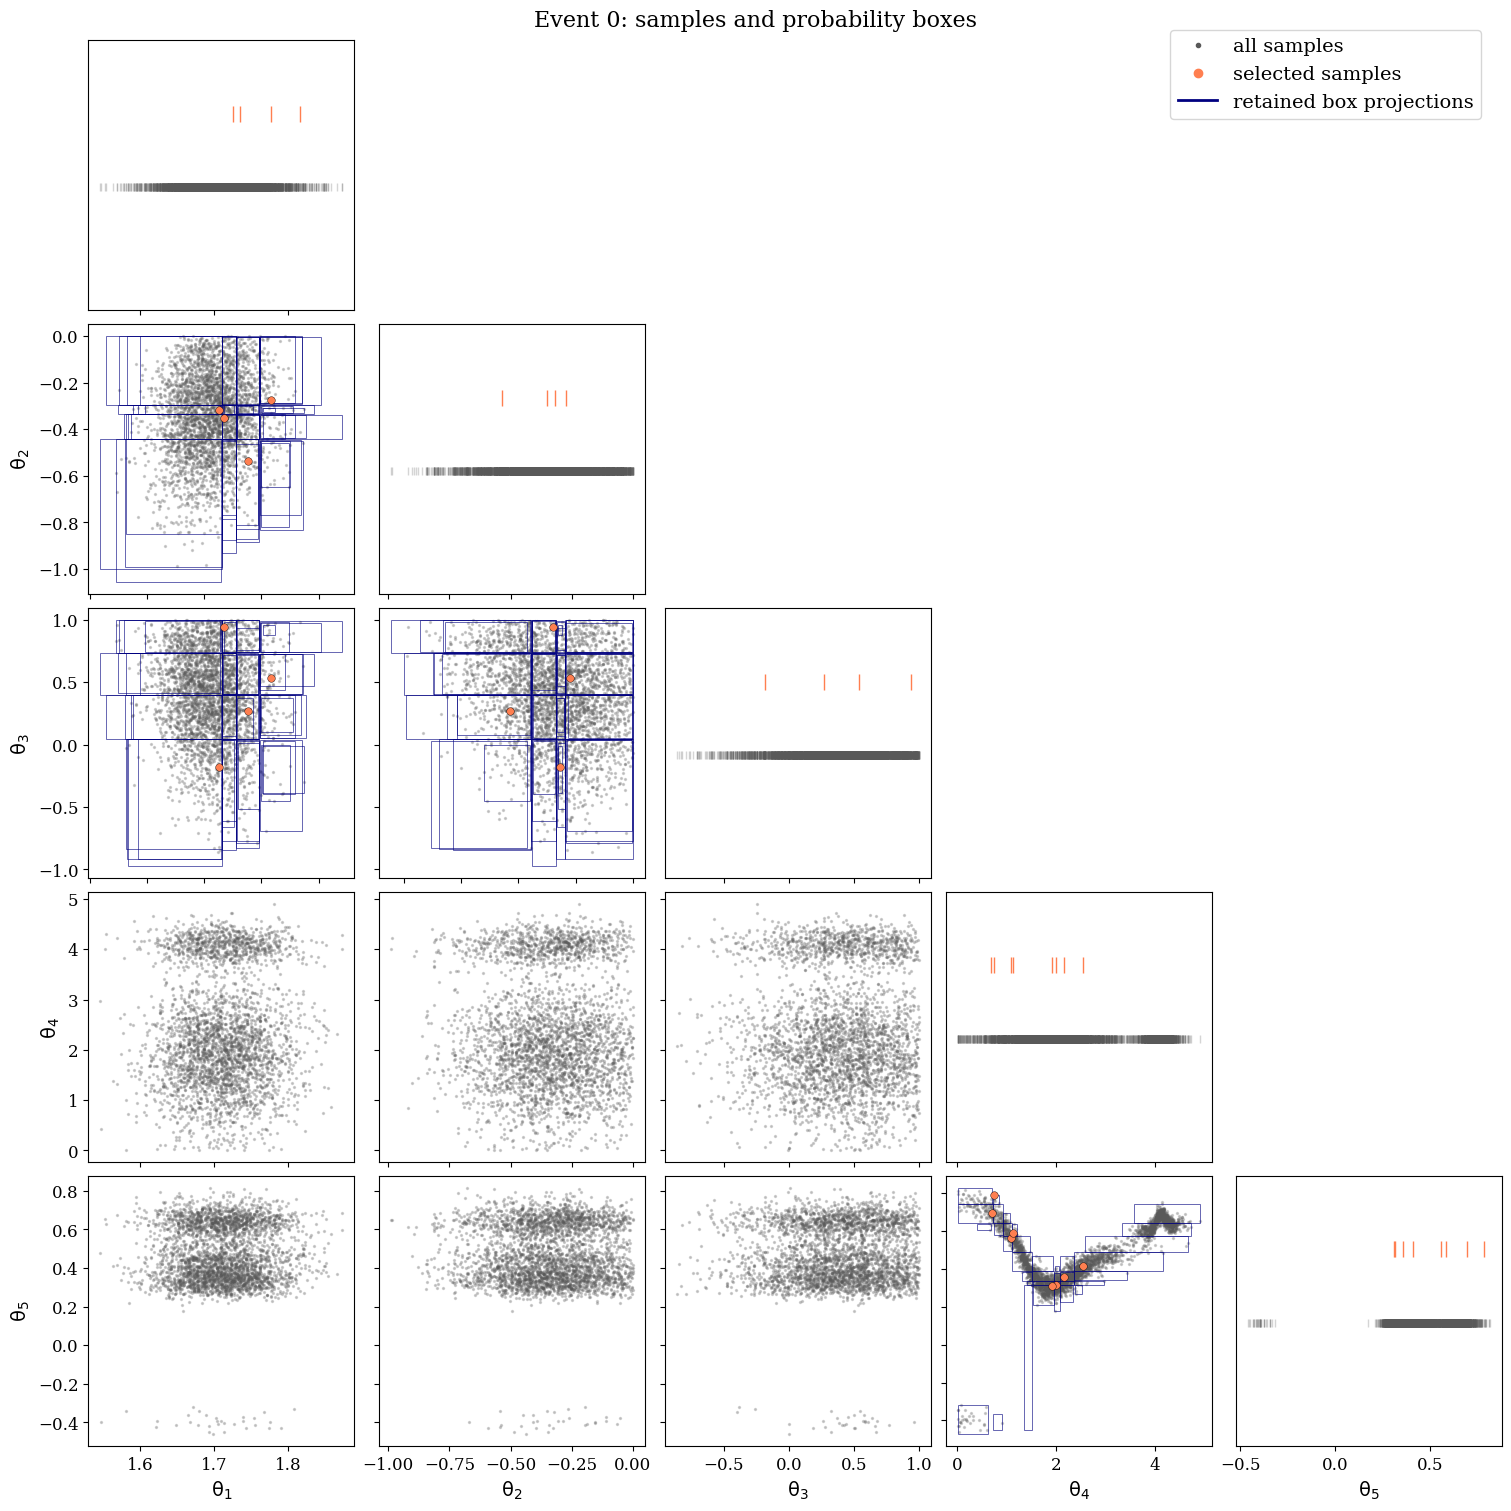

In [3]:
labels = [r'$\theta_1$', r'$\theta_2$', r'$\theta_3$',
          r'$\theta_4$', r'$\theta_5$']
shown = samples[::max(1, len(samples) // 3000)]
fig, axes = plt.subplots(5, 5, figsize=(15, 15), constrained_layout=True)
for row in range(5):
    for col in range(5):
        ax = axes[row, col]
        if row < col:
            ax.set_visible(False)
            continue
        if row == col:
            ax.plot(shown[:, col], np.zeros(len(shown)), '|', color='0.35', alpha=.25)
            chosen = selected_3d[:, col] if col < 3 else selected_2d[:, col - 3]
            ax.plot(chosen, np.full(len(chosen), .06), '|', color='coral', markersize=11)
            ax.set_ylim(-.1, .12)
            ax.set_yticks([])
        else:
            ax.scatter(shown[:, col], shown[:, row], s=2, color='0.35', alpha=.25,
                       rasterized=True)
            if row < 3:
                boxes, chosen, x, y = boxes_3d, selected_3d, col, row
            elif col >= 3:
                boxes, chosen, x, y = boxes_2d, selected_2d, col - 3, row - 3
            else:
                boxes = None
            if boxes is not None:
                for lower, upper in zip(boxes.lower, boxes.upper):
                    ax.add_patch(Rectangle((lower[x], lower[y]),
                                           upper[x] - lower[x], upper[y] - lower[y],
                                           fill=False, edgecolor='navy', linewidth=.7,
                                           alpha=.6))
                ax.scatter(chosen[:, x], chosen[:, y], s=30, color='coral',
                           edgecolor='black', linewidth=.3, zorder=5)
        if row == 4:
            ax.set_xlabel(labels[col])
        else:
            ax.set_xticklabels([])
        if col == 0 and row > 0:
            ax.set_ylabel(labels[row])
        elif col > 0 and row > col:
            ax.set_yticklabels([])

fig.legend(handles=[Line2D([], [], marker='.', linestyle='', color='0.35', label='all samples'),
                    Line2D([], [], marker='o', linestyle='', color='coral', label='selected samples'),
                    Line2D([], [], color='navy', label='retained box projections')],
           loc='upper right', bbox_to_anchor=(.99, .99), frameon=True)
fig.suptitle(f'Event {idx}: samples and probability boxes', fontsize=16)
if save_plots:
    fig.savefig(project_root / 'validation' / f'event_{idx}_samples_boxes.jpg', dpi=200)
plt.show()

## Density in the retained boxes

Color is the recomputed constant density in each full-dimensional box after shrinking. The first three panels project 3D boxes onto coordinate pairs, so several differently colored boxes can appear in the same projected area. The final panel shows the actual nonoverlapping 2D boxes. The color scales are separate because 3D and 2D densities have different units.

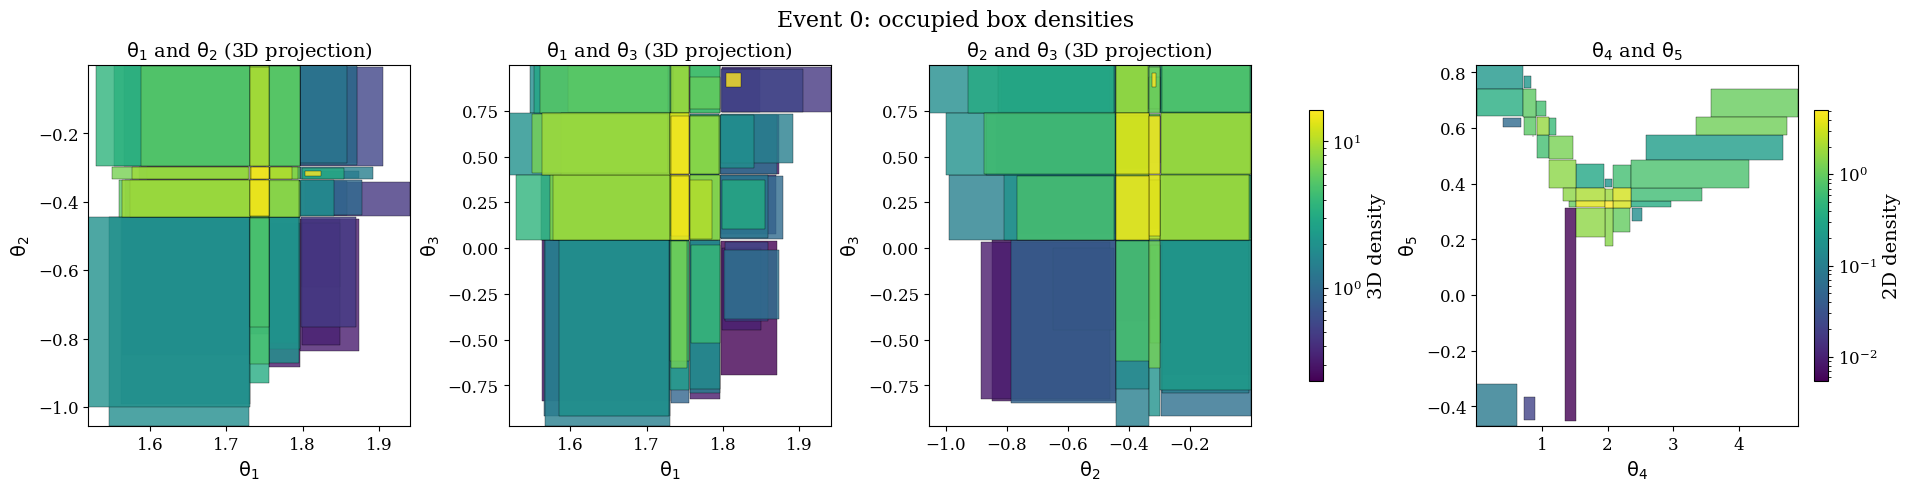

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), constrained_layout=True)
norm_3d = LogNorm(vmin=boxes_3d.density.min(), vmax=boxes_3d.density.max())
norm_2d = LogNorm(vmin=boxes_2d.density.min(), vmax=boxes_2d.density.max())
for ax, (x, y) in zip(axes, ((0, 1), (0, 2), (1, 2), (3, 4))):
    if x < 3:
        boxes, norm, local_x, local_y = boxes_3d, norm_3d, x, y
    else:
        boxes, norm, local_x, local_y = boxes_2d, norm_2d, x - 3, y - 3
    # Draw high-density boxes last where their 3D projections overlap.
    for k in np.argsort(boxes.density):
        lower, upper = boxes.lower[k], boxes.upper[k]
        ax.add_patch(Rectangle((lower[local_x], lower[local_y]),
                               upper[local_x] - lower[local_x],
                               upper[local_y] - lower[local_y],
                               facecolor=plt.cm.viridis(norm(boxes.density[k])),
                               edgecolor='black', linewidth=.3, alpha=.8))
    ax.set_xlim(samples[:, x].min(), samples[:, x].max())
    ax.set_ylim(samples[:, y].min(), samples[:, y].max())
    ax.set_xlabel(labels[x])
    ax.set_ylabel(labels[y])
    suffix = ' (3D projection)' if x < 3 else ''
    ax.set_title(f'{labels[x]} and {labels[y]}{suffix}')

fig.colorbar(ScalarMappable(norm=norm_3d, cmap='viridis'), ax=list(axes[:3]),
             shrink=.75, label=r'3D density')
fig.colorbar(ScalarMappable(norm=norm_2d, cmap='viridis'), ax=axes[3],
             shrink=.75, label=r'2D density')
fig.suptitle(f'Event {idx}: occupied box densities', fontsize=16)
if save_plots:
    fig.savefig(project_root / 'validation' / f'event_{idx}_densities.jpg', dpi=200)
plt.show()